In [1]:
#hit shift and enter at the same time to activate this code
import h5py
from matplotlib import pyplot as plt
import numpy as np
import cv2
from pathlib import Path
from PIL import Image

def dilation_subtraction(Local_dir, Save_dir):
    '''
    input = Local_dir, i.e. where the segmentation files (h5 format) are stored
    output = tiff and h5 files of the outlines saved to the Save_Dir
    
    both Local_dir and Save_dir should be inside ""
    
    put double \\ at end of path to put in folder
    
    ***NOTE***: it is essential that you do NOT have random h5 files (including outputs from the last run) in the Local_dir
    '''
    
    local_dir = Local_dir
    save_dir = Save_dir

    # image processing
    segs = Path(local_dir).glob("*.h5")

    for seg in segs:
        seg = str(seg)
        with h5py.File(seg, "r") as f:
            # List all groups
            keys = list(f.keys())[0]
            data_seg = np.array(f[keys])

        # process data_seg to get the right shape and color
        data_seg = data_seg.reshape(data_seg.shape[1], data_seg.shape[2])
        data_seg -= 2
        data_seg = np.absolute(data_seg)

        # dilation, tunable hyperperameters: kernal size, iterations
        kernel = np.ones((3,3), np.uint8)
        dilated_data_seg = cv2.dilate(data_seg, kernel, iterations = 3)

        # obtain bm_map
        bm_map = dilated_data_seg - data_seg

        # save figure
        plt.imshow(bm_map, cmap = "gray")
        plt.axis("off")
        plt.savefig(save_dir + seg.split("\\")[-1].split("_")[0] + "_bm_map.tiff", bbox_inches="tight", pad_inches = 0, dpi = 556.5)
        plt.show()
        
        
       ##### Open the saved image - USE THE FOLLOWING CODE IF THE SIZES GET OFF, IT PRINTS THE DIMENSIONS, CHANGE DPI IN ABOVE SEGMENT TO ADJUST SAVED SIZE
                #image = Image.open(save_dir + seg.split("\\")[-1].split("_")[0] + "_bm_map.tiff")

                # Get the dimensions (width and height)
                #width, height = image.size

                # Print the dimensions
               # print("Image dimensions: {} x {}".format(width, height))

    # convert to tiff
    bm_maps = Path(save_dir).glob("*.tiff")

    for bm_map in bm_maps:
        bm_map = str(bm_map)
        bm_map_img = plt.imread(bm_map)

        bm_map_h5 = h5py.File(save_dir + bm_map.split("\\")[-1].split(".")[0] + "_h5ver.h5", "w")
        bm_map_h5["bm_map_img"] = bm_map_img
        bm_map_h5.close()

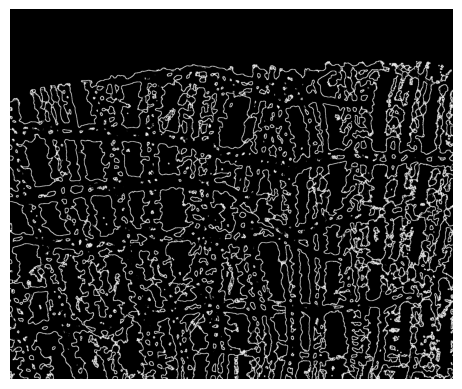

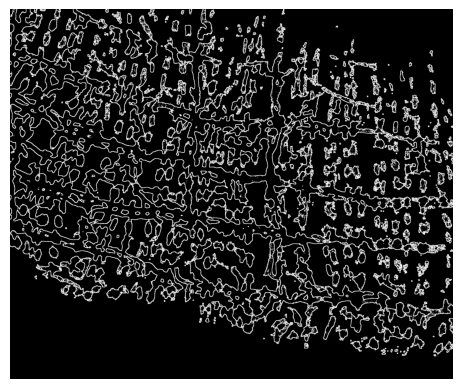

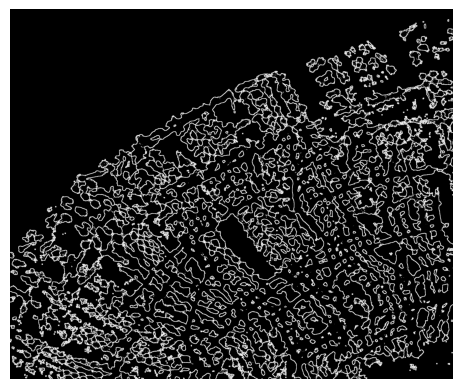

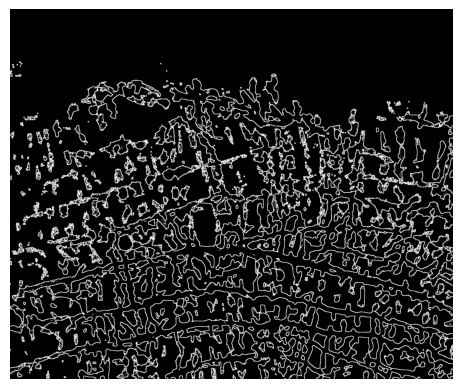

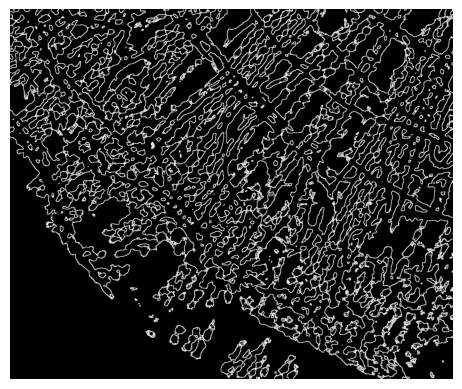

...

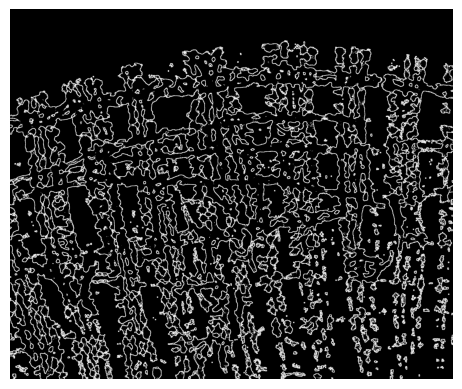

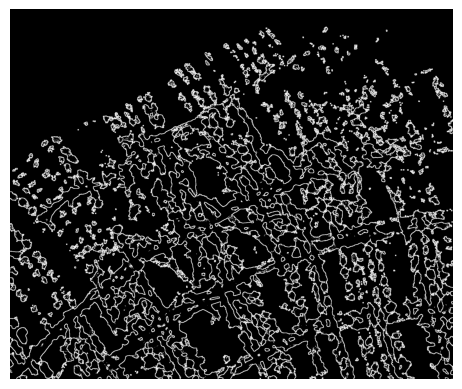

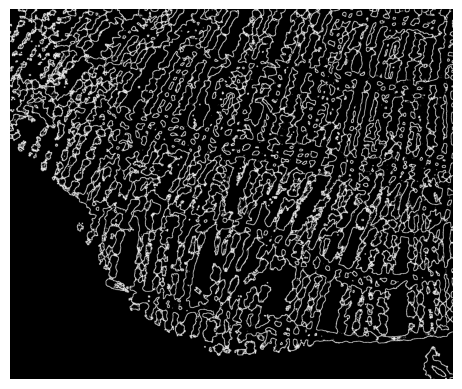

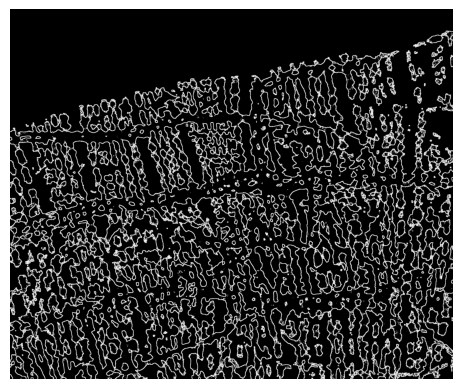

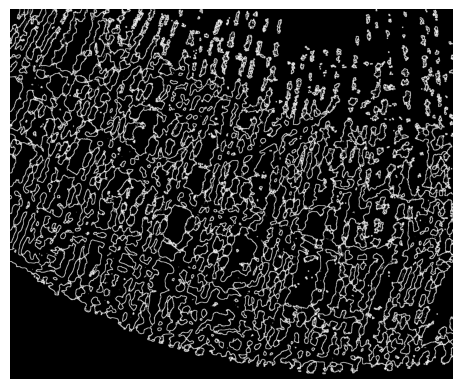

In [2]:
# dilation_subtraction (Local_dir,Save_dir)
# copy the path of the folder for "Local_dir" the original segmentation images are in, it will process them all
# make a new folder for the BM maps to go into, copy the path of this folder for them to go into for "Save_dir"
# have to put "\\" instead of one \ in between each folder or it will freak out, idk why
#hit shift and enter at the same time for it to run
dilation_subtraction("C:\\Users\\Public\\VU Basic Sciences Dropbox\\Page-McCaw Lab data\\Elkie\\Grad School\\ilastik\\2026\\CSper vkgGFP DD R1\\Muscle Segmentations\\","C:\\Users\\Public\\VU Basic Sciences Dropbox\\Page-McCaw Lab data\\Elkie\\Grad School\\ilastik\\2026\\CSper vkgGFP DD R1\\BM Maps\\")

In [3]:
import h5py
from matplotlib import pyplot as plt
import numpy as np
import cv2
from pathlib import Path

In [10]:
def dilation_subtraction(Local_dir, Save_dir):
    local_dir = Local_dir
    save_dir = Save_dir
    #can save to any folder.
    # note that you need to keep the converted h5 in a different folder from the segmentation h5
    segs = Path(local_dir).glob("*.h5")

    for seg in segs:
        seg = str(seg)
        with h5py.File(seg, "r") as f:
            # List all groups
            keys = list(f.keys())[0]
            data_seg = np.array(f[keys])

        # process data_seg to get the right shape and color
        data_seg = data_seg.reshape(data_seg.shape[2], data_seg.shape[3])
        data_seg -= 2
        data_seg = np.absolute(data_seg)

        # dilation, tunable hyperperameters: kernal size, iterations
        kernel = np.ones((3,3), np.uint8)
        dilated_data_seg = cv2.dilate(data_seg, kernel, iterations = 3)

        # obtain bm_map
        bm_map = dilated_data_seg - data_seg

        # save figure
        plt.imshow(bm_map, cmap = "gray")
        plt.axis("off")
        plt.savefig(save_dir + seg.split("\\")[-1].split("_")[0] + "_bm_map.tiff", bbox_inches="tight", pad_inches = 0, dpi = 281.5)
        plt.show()

    # convert to tiff
    bm_maps = Path(save_dir).glob("*.tiff")

    for bm_map in bm_maps:
        bm_map = str(bm_map)
        bm_map_img = plt.imread(bm_map)

        bm_map_h5 = h5py.File(save_dir + bm_map.split("\\")[-1].split(".")[0] + "_h5ver.h5", "w")
        bm_map_h5["bm_map_img"] = bm_map_img
        bm_map_h5.close()

In [11]:
# type here "dilation_subtraction("local Dir","Save Dir")" and run
dilation_subtraction("C:\\Users\\kathe\\Dropbox (VU Basic Sciences)\\Elkie\\ilastik\\Batch WalkThrough\\Trial 1 New Batch\\Simple Segmentation\\","C:\\Users\\kathe\\Dropbox (VU Basic Sciences)\\Elkie\\ilastik\\Batch WalkThrough\\Trial 1 New Batch\\BM_Maps\\")

IndexError: tuple index out of range

In [ ]:
# segmentation result from model:
seg = "C:\\Users\\kathe\\Dropbox (VU Basic Sciences)\\Elkie\\ilastik\\Macro Trial\\0 days 29 Gut 20_Simple Segmentation Stage 2.h5"
with h5py.File(seg, "r") as f:
    # List all groups
    keys = list(f.keys())[0]
    data_seg = np.array(f[keys])


data_seg = data_seg.reshape(data_seg.shape[2], data_seg.shape[3])
data_seg.shape
print(data_seg, data_seg.dtype)

data_seg -= 2
data_seg = np.absolute(data_seg)
np.unique(data_seg)

In [ ]:
plt.imshow(data_seg, cmap = "gray")
plt.axis("off")
plt.show()

In [ ]:
kernel = np.ones((3,3), np.uint8)
dilated_data_seg = cv2.dilate(data_seg, kernel, iterations = 3)
dilated_data_seg.shape

In [ ]:
plt.imshow(dilated_data_seg, cmap = "gray")
plt.axis("off")
plt.show()

In [ ]:
bm_map = dilated_data_seg - data_seg
plt.imshow(bm_map, cmap = "gray")
plt.axis("off")
plt.savefig("test.tiff", bbox_inches="tight", pad_inches = 0, dpi = 281.5)
plt.show()
bm_map.shape

In [ ]:
img_path = "C:\\Users\\kathe\\Dropbox (VU Basic Sciences)\\Elkie\\ilastik\\Macro Trial\\0 days 29 Gut 20_bm_map.tiff"

In [ ]:
test_h5 = h5py.File("test.h5", "w")
test_h5["img"] = img
test_h5.close()

In [ ]:
img = plt.imread(img_path)
img.shape

In [ ]:
plt.imshow(img)
plt.show()

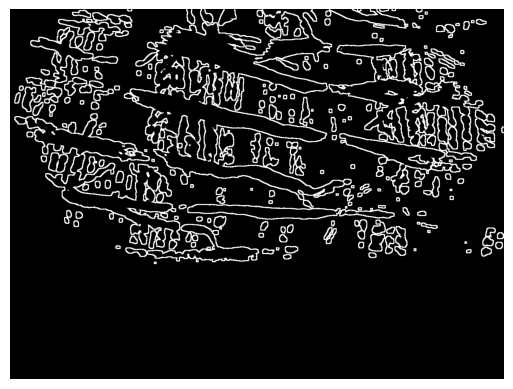

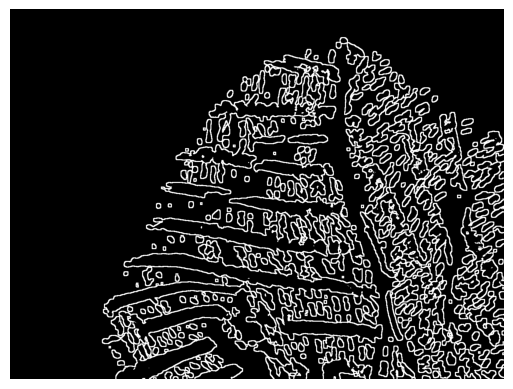

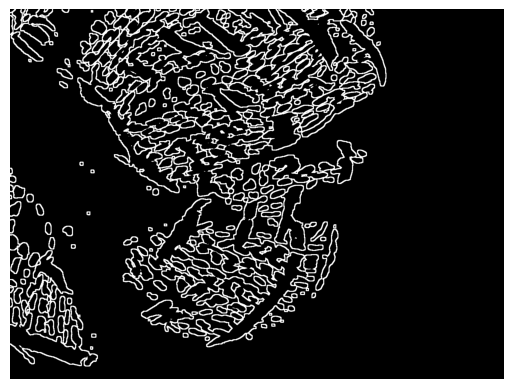

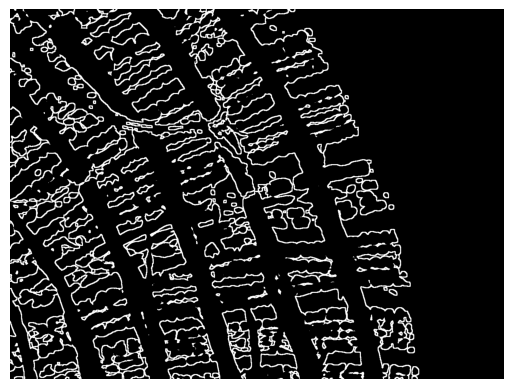

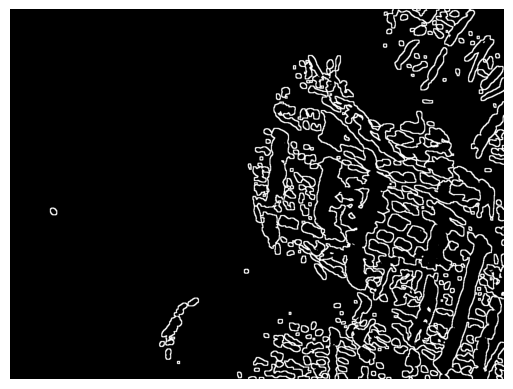

In [6]:
local_dir = "C:\\Users\\kathe\\Dropbox (VU Basic Sciences)\\Elkie\\ilastik\\Macro Trial\\"
save_dir = "C:\\Users\\kathe\\Dropbox (VU Basic Sciences)\\Elkie\\ilastik\\Macro Trial\\"
#can save to any folder.
# note that you need to keep the converted h5 in a different folder from the segmentation h5
segs = Path(local_dir).glob("*.h5")

for seg in segs:
    seg = str(seg)
    with h5py.File(seg, "r") as f:
        # List all groups
        keys = list(f.keys())[0]
        data_seg = np.array(f[keys])
        
    # process data_seg to get the right shape and color
    data_seg = data_seg.reshape(data_seg.shape[2], data_seg.shape[3])
    data_seg -= 2
    data_seg = np.absolute(data_seg)
    
    # dilation, tunable hyperperameters: kernal size, iterations
    kernel = np.ones((3,3), np.uint8)
    dilated_data_seg = cv2.dilate(data_seg, kernel, iterations = 3)
    
    # obtain bm_map
    bm_map = dilated_data_seg - data_seg
    
    # save figure
    plt.imshow(bm_map, cmap = "gray")
    plt.axis("off")
    plt.savefig(save_dir + seg.split("\\")[-1].split("_")[0] + "_bm_map.tiff", bbox_inches="tight", pad_inches = 0, dpi = 281.5)
    plt.show()
    
# convert to tiff
bm_maps = Path(save_dir).glob("*.tiff")

for bm_map in bm_maps:
    bm_map = str(bm_map)
    bm_map_img = plt.imread(bm_map)
    
    bm_map_h5 = h5py.File(save_dir + bm_map.split("\\")[-1].split(".")[0] + "_h5ver.h5", "w")
    bm_map_h5["bm_map_img"] = bm_map_img
    bm_map_h5.close()

In [ ]:
a = "C:\Users\kathe\Dropbox (VU Basic Sciences)\Elkie\ilastik\Macro Trial\0 days 29 Gut 20_bm_map.tiff"

In [ ]:
a.split("\\")[-1].split("_")[0]

In [ ]:
local_dir = "C:\\Users\\kathe\\Dropbox (VU Basic Sciences)\\Elkie\\ilastik\\Macro Trial\\"
segs = Path(local_dir).glob("*.h5")

segs_list = []

for seg in segs:
    segs_list.append(str(seg))
    
print(segs_list)